# Building portfolios through chronological folds

Each test prediction must come from a sequence fitted only on that fold's training observations:

$$
D_{\mathcal T_k}\longrightarrow\widehat{\mathcal V}_k\longrightarrow\widehat\theta_k\longrightarrow\widehat w_k\longrightarrow\widehat y_{\mathcal V_k}.
$$

Here, $D_{\mathcal T_k}$ is the training data in fold $k$; $\widehat{\mathcal V}_k$ is its selected variable set; $\widehat\theta_k$ is its fitted causal estimate; $\widehat w_k$ is its constructed portfolio; $\mathcal V_k$ is the test membership; and $\widehat y_{\mathcal V_k}$ contains predictions made only for that test membership.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("10_causal_factor_protocol");
using CSV,TOML,Printf,Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookProtocolStudy.jl"))
using .BookProtocolStudy
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm,right_margin=8Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter10_random_inputs"),"protocol")
captions=Dict("protocol_stage_order"=>("The seven protocol stages in their required order.","tab:chapter28-stage-order"),"protocol_provenance"=>("Source, family, and public-data facts used by the notebooks.","tab:chapter28-provenance"),"protocol_event_horizons"=>("Public-date event labels and their declared return horizons.","tab:chapter28-event-horizons"),"protocol_overlap_matrix"=>("Pairwise overlap indicators for the declared return horizons.","tab:chapter28-overlap-matrix"),"protocol_fold_membership"=>("Purged training and test membership for each fold.","tab:chapter28-fold-membership"),"protocol_embargo_sweep"=>("Acceptance across declared embargo lengths.","tab:chapter28-embargo-sweep"),"protocol_selection_methods"=>("Declared variable-selection methods and temporal-refit requirement.","tab:chapter28-selection-methods"),"protocol_selection_refits"=>("Recorded refits within each training fold.","tab:chapter28-selection-refits"),"protocol_graph_edges"=>("Directed edges in the supplied graph.","tab:chapter28-graph-edges"),"protocol_graph_assumptions"=>("Assumptions attached to the supplied graph.","tab:chapter28-graph-assumptions"),"protocol_graph_roles"=>("Declared graph roles and ordinary-control use.","tab:chapter28-graph-roles"),"protocol_adjustment_evidence"=>("Identification evidence for the supplied back-door adjustment.","tab:chapter28-adjustment-evidence"),"protocol_stage23_rejections"=>("Graph and adjustment declarations rejected by the released checks.","tab:chapter28-stage23-rejections"),"protocol_stage23_rejection_counts"=>("Rejected cases by protocol stage.","tab:chapter28-stage23-rejection-counts"),"protocol_section1_summary"=>("Questions answered by the first three protocol stages.","tab:chapter28-section1-summary"),"protocol_fold_evidence"=>("Foldwise fitting and prediction evidence.","tab:chapter28-fold-evidence"),"protocol_fold_refits"=>("Required training-only refits in every fold.","tab:chapter28-fold-refits"),"protocol_stage4_metrics"=>("Separate explanatory and predictive evidence records.","tab:chapter28-stage4-metrics"),"protocol_public_fold_metrics"=>("Foldwise public-return measures with a training-mean comparison rule.","tab:chapter28-public-fold-metrics"),"protocol_public_data"=>("Public-return source and foldwise illustration.","tab:chapter28-public-data"),"protocol_portfolio_requirements"=>("The six required portfolio considerations and their supplied evidence.","tab:chapter28-portfolio-requirements"),"protocol_public_strategy"=>("Observed public-return path before and after declared transaction costs.","tab:chapter28-public-strategy"),"protocol_public_weights"=>("Illustrative public-return weights used only to show a portfolio record.","tab:chapter28-public-weights"),"protocol_transfer_sensitivity"=>("Transfer from intended to achieved supplied exposures.","tab:chapter28-transfer-sensitivity"),"protocol_cpcv_folds"=>("Combinatorial path contributions in the supplied record.","tab:chapter28-cpcv-folds"),"protocol_cpcv_coverage"=>("Test contributions per event and complete path.","tab:chapter28-cpcv-coverage"),"protocol_public_trial_paths"=>("Observed public-return paths for the declared three-trial family.","tab:chapter28-public-trial-paths"),"protocol_monte_carlo_record"=>("A complete Monte Carlo backtest declaration.","tab:chapter28-monte-carlo-record"),"protocol_stage456_rejections"=>("Incomplete Stage 4, Stage 5, and Stage 6 records rejected by the released checks.","tab:chapter28-stage456-rejections"),"protocol_section2_summary"=>("Questions answered by Stages 4 through 6.","tab:chapter28-section2-summary"),"protocol_trial_family_identity"=>("The same declared trial family appears in Stages 6 and 7.","tab:chapter28-trial-family-identity"),"protocol_family_partitions"=>("The declared, disjoint partitions of the trial family.","tab:chapter28-family-partitions"),"protocol_partition_membership"=>("Trial membership in each declared family partition.","tab:chapter28-partition-membership"),"protocol_partition_checks"=>("Complete partition evidence is accepted and malformed partitions are rejected.","tab:chapter28-partition-checks"),"protocol_public_p_values"=>("Dependence-adjusted evidence from the three declared public-return paths.","tab:chapter28-public-p-values"),"protocol_public_adjustments"=>("Raw and adjusted values for the declared public-return trial family.","tab:chapter28-public-adjustments"),"protocol_adjustment_scope"=>("The distinct roles of the Stage 7 choices used or listed here.","tab:chapter28-adjustment-scope"),"protocol_dsr_inputs"=>("Declared inputs required for the deflated Sharpe calculation.","tab:chapter28-dsr-inputs"),"protocol_dsr_sensitivity"=>("Sensitivity of the selection benchmark to the effective trial count.","tab:chapter28-dsr-sensitivity"),"protocol_moment_grid"=>("Feasible and infeasible skewness-kurtosis pairs.","tab:chapter28-moment-grid"),"protocol_dependence_record"=>("Evidence required when trials and return observations are dependent.","tab:chapter28-dependence-record"),"protocol_trial_correlation"=>("Correlation among the three declared public-return paths.","tab:chapter28-trial-correlation"),"protocol_record_checks"=>("Immutability checks for the seven stage records and complete report.","tab:chapter28-record-checks"),"protocol_public_names"=>("All twelve released protocol names covered by the chapter notebooks.","tab:chapter28-public-names"),"protocol_stage7_rejections"=>("Incomplete or inconsistent Stage 7 records rejected by the released checks.","tab:chapter28-stage7-rejections"),"protocol_stage7_rejection_groups"=>("Rejected Stage 7 cases grouped by the missing or inconsistent evidence.","tab:chapter28-stage7-rejection-groups"),"protocol_section3_summary"=>("Questions answered by the Stage 7 evidence record.","tab:chapter28-section3-summary"));


## Training-only refits recorded in every fold

Row,Fold,Training observations,Test observations,Fit equals training,Predictions equal test,Refit record,Refitted parts
,String,Int64,Int64,String,String,String,Int64
1,F1,4,2,Yes,Yes,R1,3
2,F2,4,2,Yes,Yes,R2,3
3,F3,4,2,Yes,Yes,R3,3


Row,Fold,Part,Recorded
,String,String,String
1,F1,Variable Selection,Yes
2,F1,Causal Estimation,Yes
3,F1,Portfolio Construction,Yes
4,F2,Variable Selection,Yes
5,F2,Causal Estimation,Yes
6,F2,Portfolio Construction,Yes
7,F3,Variable Selection,Yes
8,F3,Causal Estimation,Yes
9,F3,Portfolio Construction,Yes


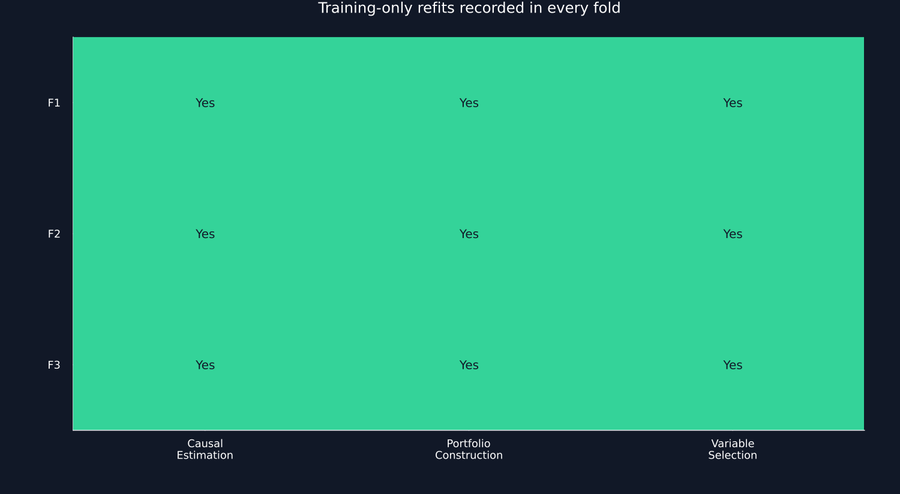

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    caption,label=captions[name]
    save_table(shown,paths,name;caption=caption,label=label)
    return nothing
end
dates,industry_names,industry_returns=protocol_returns()
observation_ids=Tuple("event-".*string.(dates[1:6]))
report=validate_causal_factor_protocol(valid_protocol_report(observation_ids))
validation=report.causal_explanatory_and_predictive_power.validation
fold_evidence=frame(["Fold","Training observations","Test observations","Fit equals training","Predictions equal test","Refit record","Refitted parts"],[(uppercase(fold.fold_id),length(fold.train_ids),length(fold.test_ids),Set(fold.fit_ids)==Set(fold.train_ids),Set(fold.prediction_ids)==Set(fold.test_ids),uppercase(fold.refit_id),length(fold.refit_components)) for fold in validation.folds])
table(fold_evidence,"protocol_fold_evidence")
component_table=frame(["Fold","Part","Recorded"],[(uppercase(fold.fold_id),human_label(component),component in fold.refit_components) for fold in validation.folds for component in ("VARIABLE_SELECTION","CAUSAL_ESTIMATION","PORTFOLIO_CONSTRUCTION")])
table(component_table,"protocol_fold_refits")
component_labels=sort(unique(component_table.Part))
refit_matrix=[Int(only(component_table[(component_table.Fold.==fold).&(component_table.Part.==part),:Recorded])) for fold in sort(unique(component_table.Fold)),part in component_labels]
figure=heatmap_record(refit_matrix,replace.(component_labels," "=>"\n"),sort(unique(component_table.Fold));title="Training-only refits recorded in every fold",colors=[palette.rose,palette.green],labels=ifelse.(refit_matrix.==1,"Yes","No"))
save_figure(figure,paths,"protocol_fold_refits")


## Keeping explanation separate from prediction

Return-size evidence can use separate explanatory and predictive measures:

$$
R^2_{\mathrm{train}}=1-\frac{\sum_{i\in\mathcal T_k}(y_i-\widehat y_i)^2}{\sum_{i\in\mathcal T_k}(y_i-\bar y_{\mathcal T_k})^2},
\qquad
\operatorname{MSE}_{\mathrm{test}}=\frac{1}{|\mathcal V_k|}\sum_{i\in\mathcal V_k}(y_i-\widehat y_i)^2.
$$

Here, $R^2_{\mathrm{train}}$ is explanatory fit on training observations; $\operatorname{MSE}_{\mathrm{test}}$ is predictive error on held-out observations; $y_i$ is the observed return; $\widehat y_i$ is its fitted or predicted value; $\bar y_{\mathcal T_k}$ is the training mean; $\mathcal T_k$ and $\mathcal V_k$ are training and test memberships; and $|\mathcal V_k|$ is the number of test observations.

### Fitting and prediction by chronological fold

In [2]:
stage4=report.causal_explanatory_and_predictive_power
metric_rows=[]
for (aspect,labels,evidence) in [("Explanatory",stage4.explanatory_metric_labels,stage4.explanatory_evidence_id),("Predictive",stage4.predictive_metric_labels,stage4.predictive_evidence_id)]
    append!(metric_rows,[(aspect,human_label(label),evidence) for label in labels])
end
metric_table=frame(["Evidence aspect","Measure","Evidence record"],metric_rows)
table(metric_table,"protocol_stage4_metrics")
target_name=industry_names[1]
feature_names=industry_names[2:4]
design_dates=dates[2:end]
design=hcat(ones(length(design_dates)),industry_returns[1:end-1,2:4])
targets=industry_returns[2:end,1]
public_metric_rows=[]
prediction_rows=[]
coefficient_rows=[]
for fold in [2023,2024,2025]
    training=findall(design_dates.<=Date(fold-1,12,31))
    heldout=findall(Date(fold,1,1).<=design_dates.<=Date(fold,12,31))
    x_train,x_test=design[training,:],design[heldout,:]
    y_train,y_test=targets[training],targets[heldout]
    coefficients=x_train\y_train
    fitted,predicted=x_train*coefficients,x_test*coefficients
    benchmark=fill(mean(y_train),length(heldout))
    r_squared=1-sum(abs2,y_train-fitted)/sum(abs2,y_train.-mean(y_train))
    test_mse=mean(abs2,y_test-predicted)
    benchmark_mse=mean(abs2,y_test-benchmark)
    spearman=cor(average_ranks(y_test),average_ranks(predicted))
    push!(public_metric_rows,(string(fold),length(training),length(heldout),r_squared,test_mse,benchmark_mse,spearman))
    append!(prediction_rows,[(design_dates[row],string(fold),y_test[index],predicted[index],benchmark[index]) for (index,row) in enumerate(heldout)])
    push!(coefficient_rows,(fold,coefficients...))
end
public_metrics=frame(["Fold","Training observations","Test observations","Training R squared","Test mean squared error","Simple-rule mean squared error","Test Spearman correlation"],public_metric_rows)
prediction_frame=frame(["Date","Fold","Observed return","Predicted return","Simple-rule prediction"],prediction_rows)
sort!(prediction_frame,:Date)
table(public_metrics,"protocol_public_fold_metrics");


Row,Evidence aspect,Measure,Evidence record
,String,String,String
1,Explanatory,R squared,explanatory-evidence
2,Predictive,Mean squared error,predictive-evidence
3,Predictive,Spearman Correlation,predictive-evidence


Row,Fold,Training observations,Test observations,Training R squared,Test mean squared error,Simple-rule mean squared error,Test Spearman correlation
,String,Int64,Int64,Float64,Float64,Float64,Float64
1,2023,1007,250,0.0351432,0.000224826,0.000216725,-0.00245806
2,2024,1257,252,0.0271281,0.000274546,0.000276579,0.0256689
3,2025,1509,250,0.0246055,0.000225734,0.000225029,0.0867561


### Expanding public-return illustration

Row,Data item,Value
,String,Any
1,Archive,Kenneth R. French 49 Industry Portfolios daily returns
2,Date range,2019-01-02 to 2025-12-31
3,Target series,Agric
4,Lagged public predictors,3
5,Held-out prediction years,3


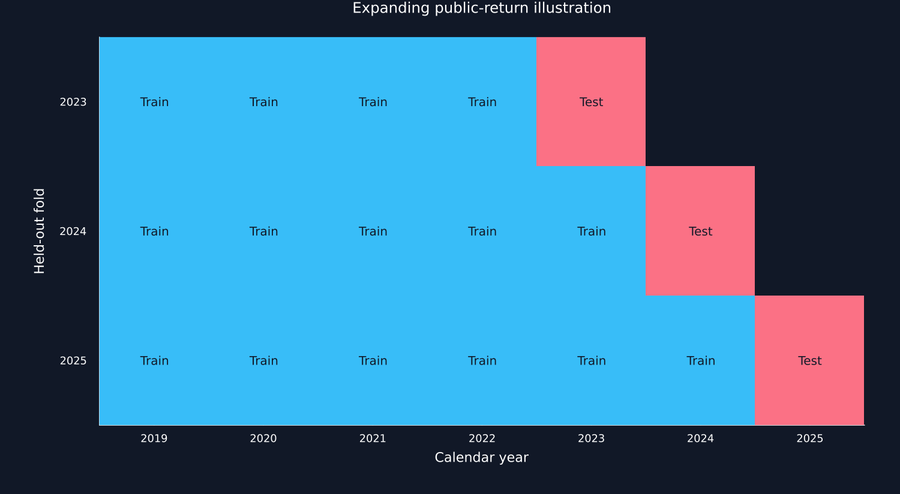

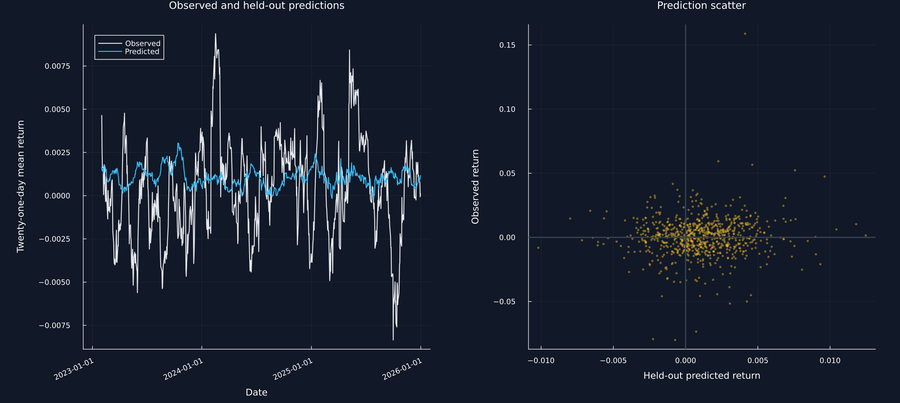

In [2]:
data_table=frame(["Data item","Value"],[("Archive","Kenneth R. French 49 Industry Portfolios daily returns"),("Date range",string(first(dates))*" to "*string(last(dates))),("Target series",target_name),("Lagged public predictors",length(feature_names)),("Held-out prediction years",3)])
table(data_table,"protocol_public_data")
save_data(hcat(DataFrame("Date"=>dates),DataFrame(industry_returns[:,1:12],industry_names[1:12])),paths,"protocol_public_inputs")
save_data(frame(["Fold","Intercept","Lagged predictor 1","Lagged predictor 2","Lagged predictor 3"],coefficient_rows),paths,"protocol_fold_coefficients")
year_matrix=[year<fold ? 1 : year==fold ? -1 : 0 for fold in [2023,2024,2025],year in 2019:2025]
figure=heatmap_record(year_matrix,string.(2019:2025),string.([2023,2024,2025]);title="Expanding public-return illustration",xlabel="Calendar year",ylabel="Held-out fold",colors=[palette.rose,palette.background,palette.cyan],limits=(-1,1),labels=map(value->value==1 ? "Train" : value==-1 ? "Test" : "",year_matrix))
save_figure(figure,paths,"protocol_public_folds")
prediction_means=DataFrame("Date"=>prediction_frame.Date,"Observed 21-day mean"=>rolling_mean(prediction_frame[:,"Observed return"],21),"Predicted 21-day mean"=>rolling_mean(prediction_frame[:,"Predicted return"],21))
save_data(prediction_means,paths,"protocol_prediction_rolling_means")
left=plot(prediction_means.Date,Matrix(prediction_means[:,2:3]);color=[palette.text palette.cyan],label=["Observed" "Predicted"],linewidth=1.5,xlabel="Date",ylabel="Twenty-one-day mean return",title="Observed and held-out predictions",legend=:topleft,titlefontsize=11,xrotation=25)
right=scatter(prediction_frame[:,"Predicted return"],prediction_frame[:,"Observed return"];color=palette.amber,alpha=.45,markersize=2,markerstrokewidth=0,label="",xlabel="Held-out predicted return",ylabel="Observed return",title="Prediction scatter",titlefontsize=11)
hline!(right,[0.];color=palette.grid,label="")
vline!(right,[0.];color=palette.grid,label="")
save_figure(plot(left,right;layout=(1,2),size=(1450,650)),paths,"protocol_public_predictions")


## Carrying causal estimates into portfolio decisions

The transfer coefficient compares intended and achieved exposures through their correlation:

$$
\operatorname{TC}=\frac{\sum_{j=1}^{J}(a_j-\bar a)(b_j-\bar b)}{\sqrt{\sum_{j=1}^{J}(a_j-\bar a)^2}\sqrt{\sum_{j=1}^{J}(b_j-\bar b)^2}}.
$$

Here, $\operatorname{TC}$ is the transfer coefficient; $a_j$ is the intended exposure for asset $j$; $b_j$ is the achieved exposure; $\bar a$ and $\bar b$ are their cross-asset means; and $J$ is the number of assets.

### Model fitting and predictions

In [3]:
portfolio=report.causal_portfolio_construction
portfolio_reasons=Dict("POSITION_SIZING"=>"Causal exposure X drives position size","EXPOSURE_CONTROL"=>"Collider C and descendant D are neutralized","ECONOMIC_RATIONALE"=>portfolio.economic_rationale,"FRAGILITY_STRESS_TEST"=>join(portfolio.fragility_scenarios,"; "),"TRANSACTION_COST_OPTIMIZATION"=>portfolio.cost_model_id,"TRANSFER_COEFFICIENT"=>string(portfolio.transfer_coefficient))
portfolio_table=frame(["Required consideration","Recorded evidence"],[(human_label(value),portfolio_reasons[value]) for value in portfolio.method_labels])
table(portfolio_table,"protocol_portfolio_requirements")
prediction_frame[!,"Position"]=ifelse.(prediction_frame[:,"Predicted return"].>=0,1.,-1.)
prediction_frame[!,"Gross strategy return"]=prediction_frame.Position.*prediction_frame[:,"Observed return"]
prediction_frame[!,"Turnover"]=vcat(abs(prediction_frame.Position[1]),abs.(diff(prediction_frame.Position)))
prediction_frame[!,"Net strategy return"]=prediction_frame[:,"Gross strategy return"]-.0005prediction_frame.Turnover
strategy_summary=frame(["Path","Annual mean return","Annual volatility","Annual Sharpe ratio","Total return","Average daily turnover"],[(label,252mean(values),sqrt(252)*std(values;corrected=true),sqrt(252)*mean(values)/std(values;corrected=true),prod(1 .+values)-1,mean(prediction_frame.Turnover)) for (label,values) in [("Gross",prediction_frame[:,"Gross strategy return"]),("After transaction costs",prediction_frame[:,"Net strategy return"])]])
table(strategy_summary,"protocol_public_strategy")
save_data(prediction_frame,paths,"protocol_all_predictions_and_positions")
strategy_paths=cumprod(1 .+Matrix(prediction_frame[:,["Gross strategy return","Net strategy return"]]);dims=1).-1
save_data(hcat(DataFrame("Date"=>prediction_frame.Date),DataFrame(strategy_paths,["Gross","After transaction costs"])),paths,"protocol_strategy_cumulative");


Row,Required consideration,Recorded evidence
,String,String
1,Position Sizing,Causal exposure X drives position size
2,Exposure Control,Collider C and descendant D are neutralized
3,Economic Rationale,Positions target the supplied X to Y effect.
4,Fragility Stress Test,weaken X to Y; perturb Z to X
5,Transaction Cost Optimization,cost-record
6,Transfer Coefficient,0.82


Row,Path,Annual mean return,Annual volatility,Annual Sharpe ratio,Total return,Average daily turnover
,String,Float64,Float64,Float64,Float64,Float64
1,Gross,0.162225,0.245561,0.660629,0.485138,0.868351
2,After transaction costs,0.0528128,0.24548,0.215141,0.0715664,0.868351


### Public-return illustration of transaction costs

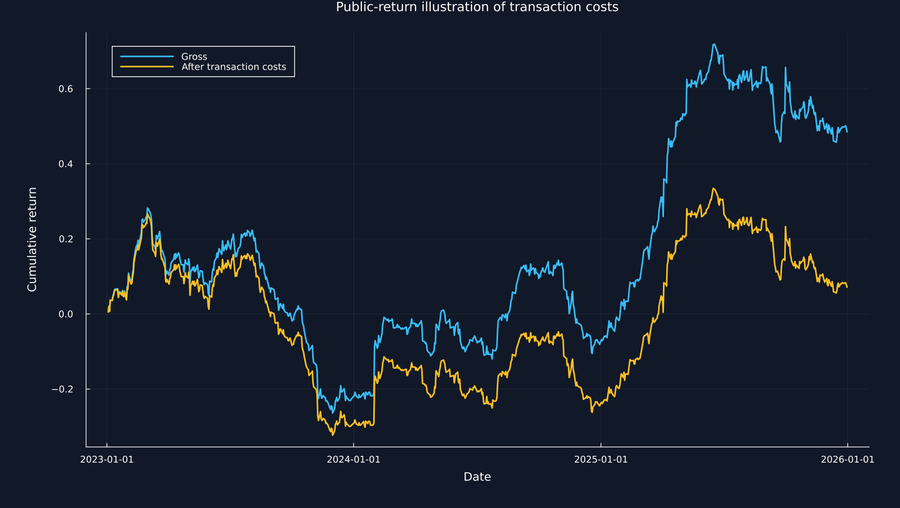

Row,Industry,Illustrative weight,Annual mean return
,String,Float64,Float64
1,Agric,0.0190539,0.103581
2,Food,-0.157169,-0.0659489
3,Soda,0.00627003,0.091283
4,Beer,-0.151804,-0.0607883
5,Smoke,0.125401,0.205889
6,Toys,0.0183224,0.102878
7,Fun,0.210534,0.287789
8,Books,0.074265,0.156696
9,Hshld,-0.081789,0.00656809


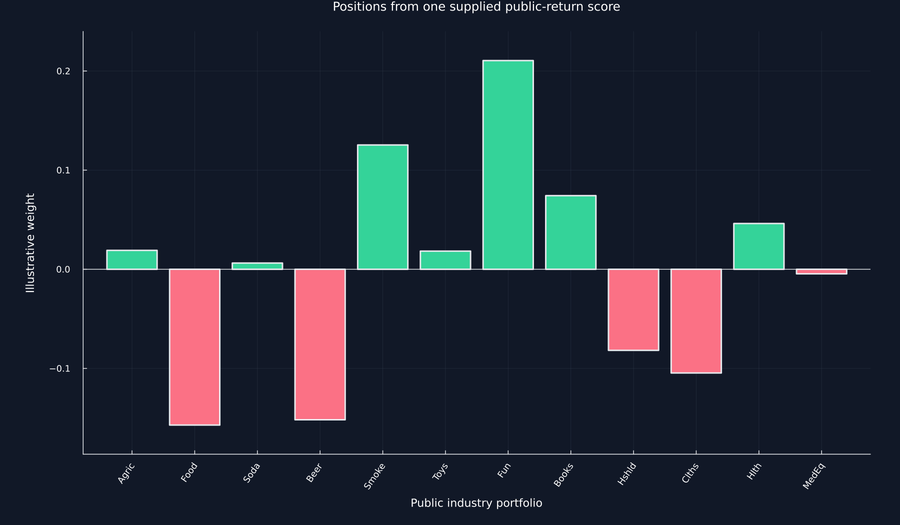

Row,Disturbance scale,Transfer coefficient,Exposure root mean squared error
,Float64,Float64,Float64
1,0.0,1.0,0.0
2,0.05,0.997933,0.0497257
3,0.1,0.985452,0.128761
4,0.2,0.939124,0.228835
5,0.4,0.725372,0.4742
6,0.8,0.571225,0.685252


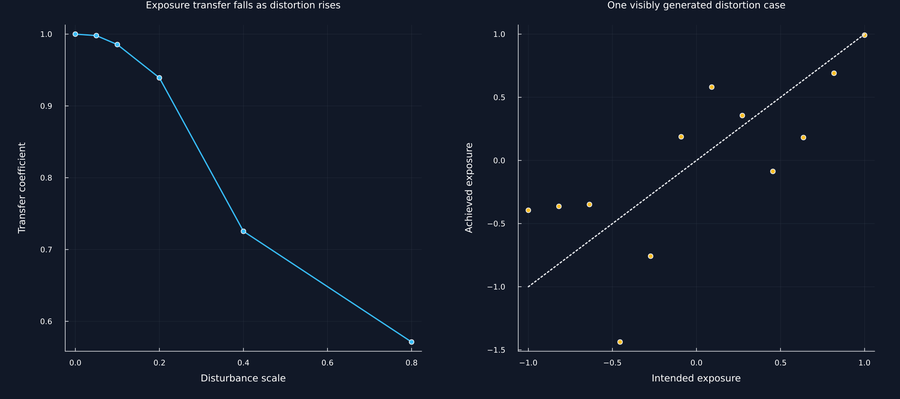

In [3]:
figure=plot(prediction_frame.Date,strategy_paths;color=[palette.cyan palette.amber],label=["Gross" "After transaction costs"],xlabel="Date",ylabel="Cumulative return",title="Public-return illustration of transaction costs",size=(1150,650))
save_figure(figure,paths,"protocol_public_strategy")
public_means=vec(mean(industry_returns[dates.>=Date(2023,1,1),1:12];dims=1))
illustrative_weights=public_means.-mean(public_means)
illustrative_weights./=sum(abs,illustrative_weights)
weight_table=DataFrame("Industry"=>industry_names[1:12],"Illustrative weight"=>illustrative_weights,"Annual mean return"=>252public_means)
table(weight_table,"protocol_public_weights")
figure=colored_bars(1:12,illustrative_weights,ifelse.(illustrative_weights.>=0,palette.green,palette.rose);xticks=(1:12,industry_names[1:12]),xrotation=55,label="",xlabel="Public industry portfolio",ylabel="Illustrative weight",title="Positions from one supplied public-return score",size=(1200,700))
hline!(figure,[0.];color=palette.text,linewidth=1,label="")
bar_headroom!(figure,illustrative_weights)
save_figure(figure,paths,"protocol_public_weights")
intended_exposure=collect(range(-1.,1.;length=12))
transfer_rows=[]
exposure_rows=[]
achieved_examples=Dict{Float64,Vector{Float64}}()
for (index,scale) in enumerate([0.,.05,.1,.2,.4,.8])
    achieved=intended_exposure+scale*vec(normal_block(store,"transfer",index))
    coefficient=cor(intended_exposure,achieved)
    push!(transfer_rows,(scale,coefficient,sqrt(mean(abs2,achieved-intended_exposure))))
    achieved_examples[scale]=achieved
    append!(exposure_rows,[(scale,row,intended_exposure[row],achieved[row]) for row in 1:12])
end
transfer_table=frame(["Disturbance scale","Transfer coefficient","Exposure root mean squared error"],transfer_rows)
table(transfer_table,"protocol_transfer_sensitivity")
save_data(frame(["Disturbance scale","Exposure","Intended","Achieved"],exposure_rows),paths,"protocol_all_exposure_disturbances")
left=plot(transfer_table[:,1],transfer_table[:,2];marker=:circle,color=palette.cyan,label="",xlabel="Disturbance scale",ylabel="Transfer coefficient",title="Exposure transfer falls as distortion rises",titlefontsize=10)
right=scatter(intended_exposure,achieved_examples[.4];color=palette.amber,label="",xlabel="Intended exposure",ylabel="Achieved exposure",title="One visibly generated distortion case",titlefontsize=10)
plot!(right,[-1,1],[-1,1];color=palette.text,linestyle=:dot,label="")
save_figure(plot(left,right;layout=(1,2),size=(1400,620)),paths,"protocol_transfer_sensitivity")


## Comparing chronological backtest paths

With $N$ time groups and $k$ tested groups per split, the number of complete combinatorial paths is:

$$
\phi=\frac{k}{N}\binom{N}{k}=\binom{N-1}{k-1}.
$$

Here, $N$ is the number of time groups; $k$ is the number tested in each split; $\binom{N}{k}$ is the number of test-group combinations; and $\phi$ is the number of complete backtest paths.

Row,Path,Fold,Training events,Test events,Refit record
,String,String,Int64,String,String
1,P1,P1-F1,4,"1, 2",P1-R1
2,P1,P1-F2,4,"3, 4",P1-R2
3,P1,P1-F3,4,"5, 6",P1-R3
4,P2,P2-F1,3,"1, 3",P2-R1
5,P2,P2-F2,3,"2, 5",P2-R2
6,P2,P2-F3,3,"4, 6",P2-R3


Row,Path,Event 1,Event 2,Event 3,Event 4,Event 5,Event 6
,String,Int64,Int64,Int64,Int64,Int64,Int64
1,P1,1,1,1,1,1,1
2,P2,1,1,1,1,1,1


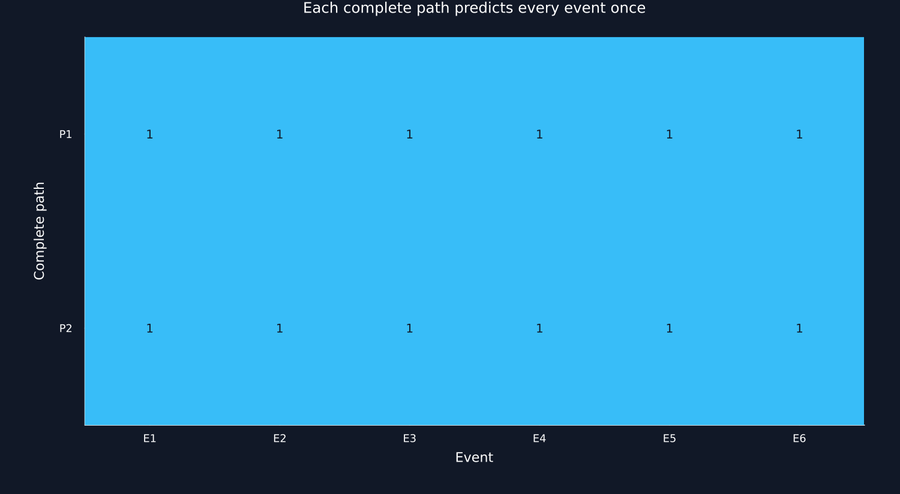

Row,Declared trial,Observations,Annual mean return,Annual volatility,Annual Sharpe ratio,Total return
,String,Int64,Float64,Float64,Float64,Float64
1,Strategy A,752,0.0852511,0.125153,0.681176,0.259942
2,Strategy B,752,-0.0383529,0.125245,-0.306224,-0.128813
3,Strategy C,752,0.0383529,0.125245,0.306224,0.0954017


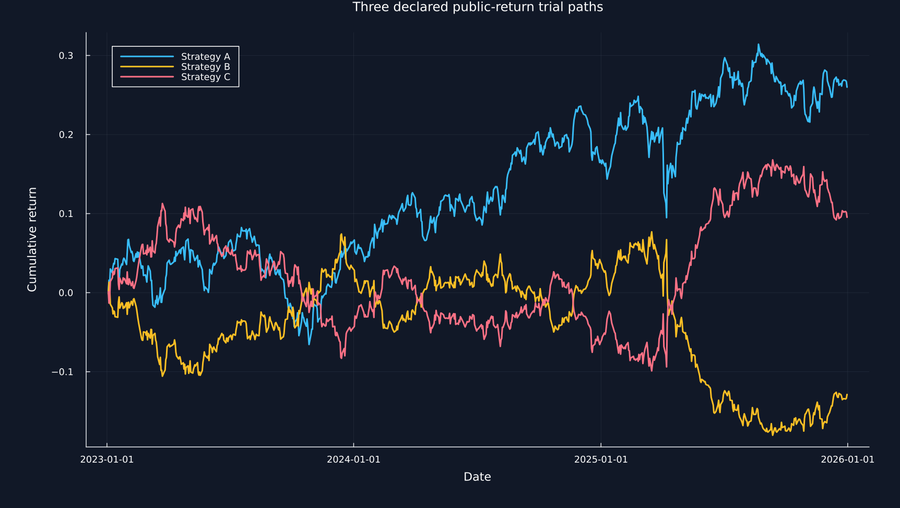

In [4]:
cpcv=report.backtest.validation
cpcv_table=frame(["Path","Fold","Training events","Test events","Refit record"],[(uppercase(fold.path_id),uppercase(fold.fold_id),length(fold.train_ids),join([string(findfirst(==(value),observation_ids)) for value in fold.test_ids],", "),uppercase(fold.refit_id)) for fold in cpcv.folds])
table(cpcv_table,"protocol_cpcv_folds")
path_matrix=[sum(value in fold.test_ids for fold in cpcv.folds if fold.path_id==path_id) for path_id in ["p1","p2"],value in observation_ids]
path_table=hcat(DataFrame("Path"=>["P1","P2"]),DataFrame(path_matrix,["Event "*string(index) for index in 1:6]))
table(path_table,"protocol_cpcv_coverage")
figure=heatmap_record(path_matrix,["E"*string(index) for index in 1:6],["P1","P2"];title="Each complete path predicts every event once",xlabel="Event",ylabel="Complete path")
save_figure(figure,paths,"protocol_cpcv_coverage")
trial_dates,trial_returns=public_trial_returns(dates,industry_returns)
trial_names=["Strategy A","Strategy B","Strategy C"]
trial_summary=frame(["Declared trial","Observations","Annual mean return","Annual volatility","Annual Sharpe ratio","Total return"],[(name,length(trial_dates),252mean(values),sqrt(252)*std(values;corrected=true),sqrt(252)*mean(values)/std(values;corrected=true),prod(1 .+values)-1) for (name,values) in zip(trial_names,eachcol(trial_returns))])
table(trial_summary,"protocol_public_trial_paths")
save_data(hcat(DataFrame("Date"=>trial_dates),DataFrame(trial_returns,trial_names)),paths,"protocol_all_trial_returns")
trial_paths=cumprod(1 .+trial_returns;dims=1).-1
save_data(hcat(DataFrame("Date"=>trial_dates),DataFrame(trial_paths,trial_names)),paths,"protocol_trial_cumulative")
figure=plot(trial_dates,trial_paths;color=[palette.cyan palette.amber palette.rose],label=permutedims(trial_names),xlabel="Date",ylabel="Cumulative return",title="Three declared public-return trial paths",size=(1150,650))
save_figure(figure,paths,"protocol_public_trial_paths")


## Recording rejected simulation evidence

A Monte Carlo backtest is interpretable only after its generation rule is stated:

$$
R_t=\mu+\sigma\varepsilon_t,
\qquad
\varepsilon_t\overset{\mathrm{iid}}{\sim}\mathcal N(0,1).
$$

Here, $R_t$ is a generated return at time $t$; $\mu$ is its supplied mean; $\sigma>0$ is its supplied standard deviation; $\varepsilon_t$ is a standard-normal shock; and iid means that the shocks are independent and identically distributed under the declared generation rule.

Row,Item,Value
,String,Any
1,Method,Monte Carlo
2,Declared trials,3
3,Temporal folds attached,No
4,Generation rule,"Gaussian returns with supplied mean, volatility, length, and random state"
5,Record accepted,Yes


Row,Case,Stage,Result,Message,Rejected
,String,String,String,String,String
1,Fit membership differs from training,Stage 4,Rejected,Stage 4: every fold must refit on its complete training membership only,Yes
2,Variable selection not refitted,Stage 4,Rejected,Stage 4: every fold must refit all required study components,Yes
3,Explanatory and predictive records merged,Stage 4,Rejected,Stage 4: explanatory and predictive evidence must be separate,Yes
4,Simple comparison record missing,Stage 4,Rejected,Stage 4: a naive benchmark identifier is required,Yes
5,Portfolio consideration omitted,Stage 5,Rejected,Stage 5: all source portfolio considerations are required,Yes
6,Transfer coefficient outside bounds,Stage 5,Rejected,Stage 5: transfer coefficient must be finite and between minus one and one,Yes
7,Trial family changed,Stage 6,Rejected,Stage 6: trial-family identifier must match the report,Yes
8,Monte Carlo rule missing,Stage 6,Rejected,Stage 6: Monte Carlo requires an explicit DGP,Yes


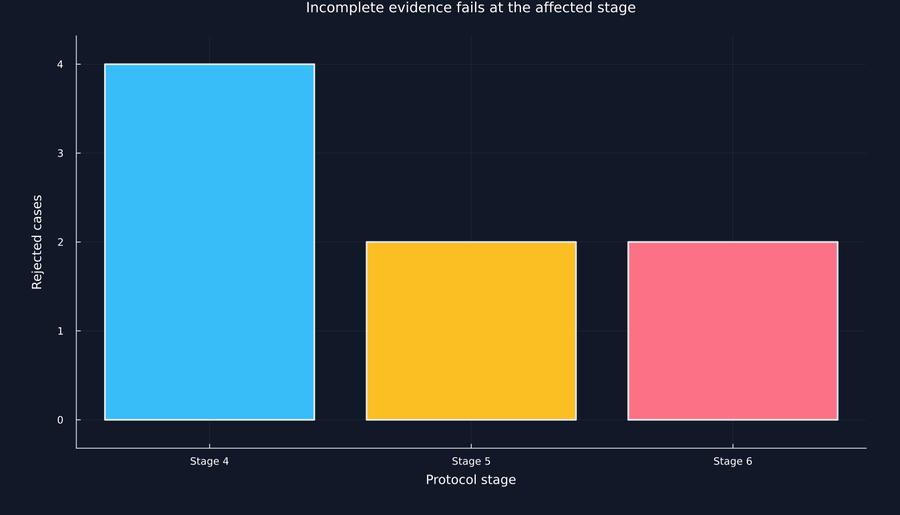

Row,Question,Evidence
,String,String
1,Were fitting and prediction memberships separated?,"Training, fit, test, and prediction identifiers"
2,Were explanatory and predictive results separated?,Different measures and evidence records
3,Was the portfolio decision fully described?,Six required considerations and a bounded transfer coefficient
4,Does every temporal path refit the required parts?,Fold-specific refit records
5,Is a Monte Carlo backtest complete?,A stated generation rule and no incompatible temporal folds


In [5]:
monte_carlo_stage=BacktestStage(method_labels=("MONTE_CARLO",),trial_family_id=report.trial_family_id,declared_trial_ids=report.declared_trial_ids,validation=nothing,monte_carlo_dgp="Gaussian returns with supplied mean, volatility, length, and random state")
monte_carlo_report=validate_causal_factor_protocol(update_record(report;backtest=monte_carlo_stage))
monte_carlo_table=frame(["Item","Value"],[("Method",human_label(monte_carlo_stage.method_labels[1])),("Declared trials",length(monte_carlo_stage.declared_trial_ids)),("Temporal folds attached","No"),("Generation rule",monte_carlo_stage.monte_carlo_dgp),("Record accepted","Yes")])
table(monte_carlo_table,"protocol_monte_carlo_record")
bad_fold=update_record(validation.folds[1];fit_ids=validation.folds[1].test_ids)
bad_validation=update_record(validation;folds=(bad_fold,validation.folds[2:end]...))
missing_refit=update_record(validation.folds[1];refit_components=("CAUSAL_ESTIMATION","PORTFOLIO_CONSTRUCTION"))
invalid_rows=[]
push!(invalid_rows,contract_case("Fit membership differs from training","Stage 4",()->validate_causal_factor_protocol(update_record(report;causal_explanatory_and_predictive_power=update_record(report.causal_explanatory_and_predictive_power;validation=bad_validation)))))
push!(invalid_rows,contract_case("Variable selection not refitted","Stage 4",()->validate_causal_factor_protocol(update_record(report;causal_explanatory_and_predictive_power=update_record(report.causal_explanatory_and_predictive_power;validation=update_record(validation;folds=((missing_refit,)...,validation.folds[2:end]...)))))))
push!(invalid_rows,contract_case("Explanatory and predictive records merged","Stage 4",()->validate_causal_factor_protocol(update_record(report;causal_explanatory_and_predictive_power=update_record(report.causal_explanatory_and_predictive_power;predictive_evidence_id=report.causal_explanatory_and_predictive_power.explanatory_evidence_id)))))
push!(invalid_rows,contract_case("Simple comparison record missing","Stage 4",()->validate_causal_factor_protocol(update_record(report;causal_explanatory_and_predictive_power=update_record(report.causal_explanatory_and_predictive_power;naive_benchmark_id="")))))
push!(invalid_rows,contract_case("Portfolio consideration omitted","Stage 5",()->validate_causal_factor_protocol(update_record(report;causal_portfolio_construction=update_record(report.causal_portfolio_construction;method_labels=report.causal_portfolio_construction.method_labels[1:end-1])))))
push!(invalid_rows,contract_case("Transfer coefficient outside bounds","Stage 5",()->validate_causal_factor_protocol(update_record(report;causal_portfolio_construction=update_record(report.causal_portfolio_construction;transfer_coefficient=1.2)))))
push!(invalid_rows,contract_case("Trial family changed","Stage 6",()->validate_causal_factor_protocol(update_record(report;backtest=update_record(report.backtest;trial_family_id="different-family")))))
push!(invalid_rows,contract_case("Monte Carlo rule missing","Stage 6",()->validate_causal_factor_protocol(update_record(report;backtest=update_record(monte_carlo_stage;monte_carlo_dgp="")))))
invalid_table=case_frame(invalid_rows)
invalid_table.Message=replace.(invalid_table.Message,"pipeline components"=>"study components")
table(invalid_table,"protocol_stage456_rejections")
invalid_counts=combine(groupby(invalid_table,:Stage;sort=true),:Rejected=>sum=>"Rejected cases")
figure=colored_bars(1:3,invalid_counts[:,2],[palette.cyan,palette.amber,palette.rose];xticks=(1:3,invalid_counts.Stage),xlabel="Protocol stage",ylabel="Rejected cases",title="Incomplete evidence fails at the affected stage",label="",size=(1050,600))
bar_headroom!(figure,invalid_counts[:,2])
save_figure(figure,paths,"protocol_stage456_rejections")
section_summary=frame(["Question","Evidence"],[["Were fitting and prediction memberships separated?","Training, fit, test, and prediction identifiers"],["Were explanatory and predictive results separated?","Different measures and evidence records"],["Was the portfolio decision fully described?","Six required considerations and a bounded transfer coefficient"],["Does every temporal path refit the required parts?","Fold-specific refit records"],["Is a Monte Carlo backtest complete?","A stated generation rule and no incompatible temporal folds"]])
table(section_summary,"protocol_section2_summary")


## Tests

In [6]:
@assert all(fold_evidence[:,"Fit equals training"])
@assert all(fold_evidence[:,"Predictions equal test"])
@assert all(component_table.Recorded)
@assert nrow(public_metrics)==3
@assert all(public_metrics[:,"Test mean squared error"].>=0)
@assert all(public_metrics[:,"Simple-rule mean squared error"].>=0)
@assert all(isfinite,public_metrics[:,"Test Spearman correlation"])
@assert nrow(prediction_frame)>700
@assert all(isfinite,Matrix(strategy_summary[:,2:end]))
@assert all(-1 .<=transfer_table[:,"Transfer coefficient"].<=1)
@assert only(transfer_table[transfer_table[:,"Disturbance scale"].==0.,"Transfer coefficient"])==1.
@assert all(path_matrix.==1)
@assert nrow(trial_summary)==3
@assert monte_carlo_report.backtest isa BacktestStage
@assert all(invalid_table.Rejected)
for name in ["protocol_fold_refits","protocol_public_folds","protocol_public_predictions","protocol_public_strategy","protocol_public_weights","protocol_transfer_sensitivity","protocol_cpcv_coverage","protocol_public_trial_paths","protocol_stage456_rejections"]
    @assert isfile(joinpath(paths.figures,name*".pdf"))
end
for name in ["protocol_fold_evidence","protocol_fold_refits","protocol_stage4_metrics","protocol_public_fold_metrics","protocol_public_data","protocol_portfolio_requirements","protocol_public_strategy","protocol_public_weights","protocol_transfer_sensitivity","protocol_cpcv_folds","protocol_cpcv_coverage","protocol_public_trial_paths","protocol_monte_carlo_record","protocol_stage456_rejections","protocol_section2_summary"]
    @assert isfile(joinpath(paths.tables,name*".tex"))
end
